### Khám phá dữ liệu EDA

In [2]:
import pandas as pd # Đọc và xử lý dữ liệu dạng bảng
import matplotlib.pyplot as plt # Vẽ biểu đồ
import seaborn as sns # Vẽ các biểu đồ thống kê

In [3]:
df = pd.read_csv("data/data.csv", sep=";")

df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
# Xóa khoảng trắng và ký tự tab ở đầu/cuối tên cột
df.columns = df.columns.str.strip()

# Xem số dòng và số cột
print("Kích thước dữ liệu:", df.shape)

# Kiểm tra tên cột, kiểu dữ liệu và số giá trị không thiếu
df.info()

Kích thước dữ liệu: (4424, 37)
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualificatio

#### Kiểm tra số dòng trùng và phân phối 3 lớp target

In [5]:
# Đếm các dòng trùng hoàn toàn
print("Số dòng trùng:", df.duplicated().sum())

# Thống kê số lượng và tỷ lệ của từng lớp
target_summary = pd.DataFrame({
    "Số lượng": df["Target"].value_counts(),
    "Tỷ lệ (%)": df["Target"].value_counts(normalize=True) * 100
})

target_summary.round(2)

Số dòng trùng: 0


,Số lượng,Tỷ lệ (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


Mục đích : Xem dataset có dòng trùng không và lớp nào chiếm nhiều hoặc ít nhất. Phân phối lớp sẽ giúp mình chọn cách chia dữ liệu và chỉ số đánh giá phù hợp.

Bộ dữ liệu không có dòng trùng hoàn toàn. Phân phối biến mục tiêu có sự mất cân bằng: Graduate chiếm 49,93%, Dropout chiếm 32,12% và Enrolled chiếm 17,95%. Vì vậy, nghiên cứu sử dụng chia dữ liệu có phân tầng, ưu tiên Macro-F1 và theo dõi Recall của lớp Dropout để đánh giá khả năng nhận diện sinh viên bỏ học.

#### Chia dữ liệu và tiền xử lý

In [6]:
from sklearn.model_selection import train_test_split

# Tách đặc trưng đầu vào và nhãn mục tiêu
X = df.drop(columns="Target")
y = df["Target"]

# Chia 80% Train và 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

# Ghép lại để thuận tiện phân tích EDA trên Train
train_df = X_train.copy()
train_df["Target"] = y_train

Train: (3539, 36)
Test: (885, 36)


#### Vẽ phân phối 3 lớp trên Train

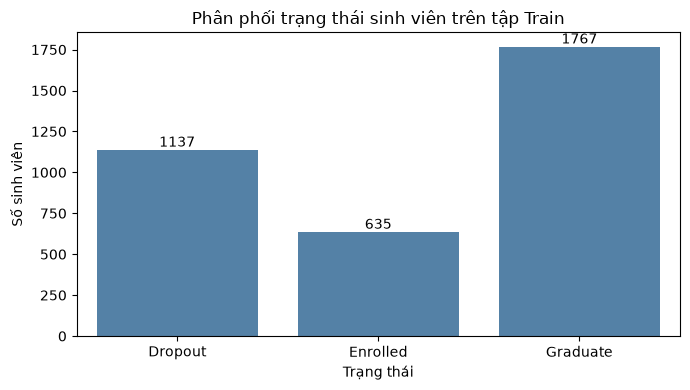

In [7]:
# Thứ tự hiển thị các lớp
class_order = ["Dropout", "Enrolled", "Graduate"]

plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=train_df,
    x="Target",
    order=class_order,
    color="steelblue"
)

# Hiển thị số lượng trên mỗi cột
ax.bar_label(ax.containers[0])

plt.title("Phân phối trạng thái sinh viên trên tập Train")
plt.xlabel("Trạng thái")
plt.ylabel("Số sinh viên")
plt.tight_layout()
plt.show()

Tập huấn luyện gồm 3.539 sinh viên, trong đó Graduate chiếm 49,93%, Dropout chiếm 32,13% và Enrolled chiếm 17,94%. Phép chia có phân tầng giữ được tỷ lệ các lớp gần tương đương dữ liệu gốc. Do phân phối lớp không đồng đều, mô hình sẽ được đánh giá bằng Macro-F1 kết hợp các chỉ số riêng từng lớp, đặc biệt là Recall của Dropout.

#### Thống kê mô tả một số biến định lượng trên Train

In [8]:
# Chọn các biến định lượng cần xem trước
numeric_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)"
]

# Tính thống kê mô tả
train_df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,3539.0,23.25,7.61,17.0,19.00,20.00,25.00,70.00
Admission grade,3539.0,126.88,14.53,95.0,117.80,126.00,134.90,190.00
Curricular units 1st sem (enrolled),3539.0,6.27,2.49,0.0,5.00,6.00,7.00,26.00
Curricular units 1st sem (approved),3539.0,4.70,3.10,0.0,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),3539.0,10.62,4.87,0.0,11.00,12.32,13.40,18.88
Curricular units 2nd sem (enrolled),3539.0,6.23,2.22,0.0,5.00,6.00,7.00,23.00
Curricular units 2nd sem (approved),3539.0,4.43,3.03,0.0,2.00,5.00,6.00,20.00
Curricular units 2nd sem (grade),3539.0,10.20,5.24,0.0,10.78,12.20,13.33,18.57


Sinh viên trong tập huấn luyện có tuổi nhập học trung vị là 20, với 50% nằm trong khoảng 19–25 tuổi. Số học phần đăng ký trung bình ở hai học kỳ tương đối ổn định, trong khi số học phần qua môn và điểm trung bình học kỳ 2 thấp hơn học kỳ 1. Một số giá trị như tuổi nhập học cao, số học phần đăng ký lớn và điểm học kỳ bằng 0 cần được kiểm tra thêm trước khi quyết định xử lý.

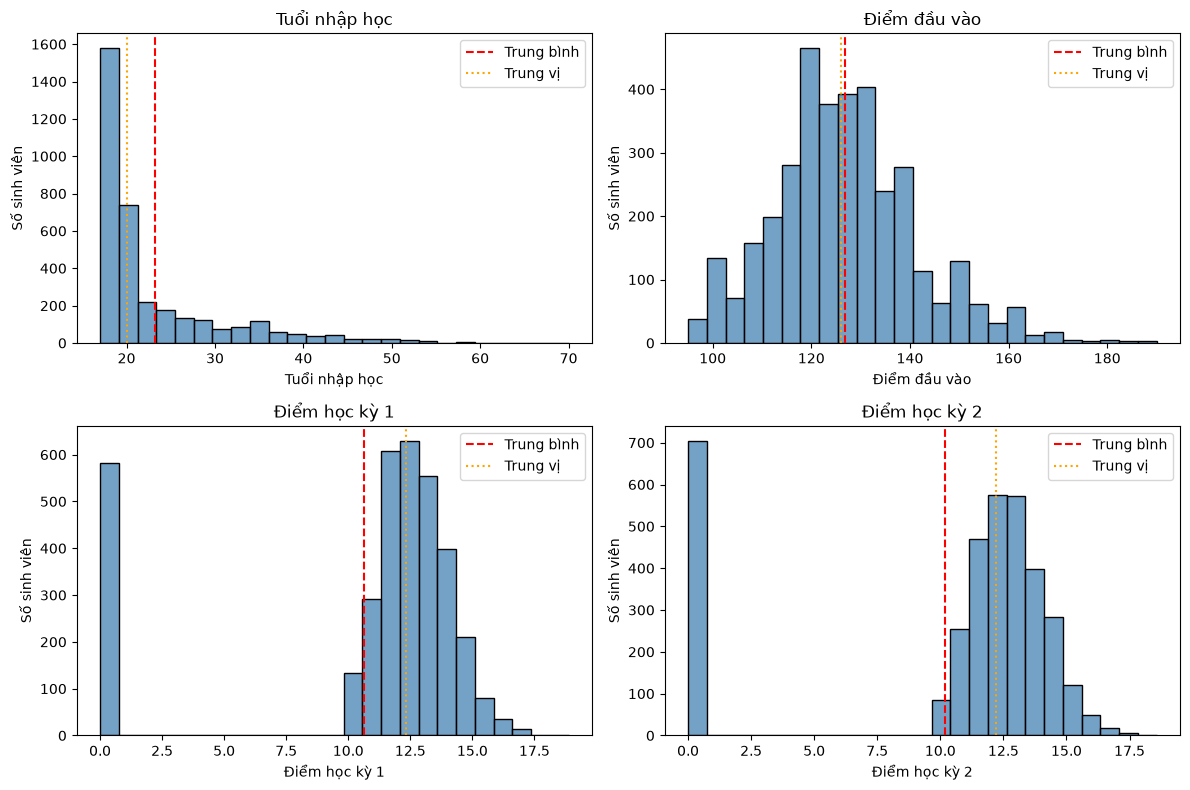

In [9]:
# Các biến và tiêu đề biểu đồ tương ứng
plot_cols = [
    ("Age at enrollment", "Tuổi nhập học"),
    ("Admission grade", "Điểm đầu vào"),
    ("Curricular units 1st sem (grade)", "Điểm học kỳ 1"),
    ("Curricular units 2nd sem (grade)", "Điểm học kỳ 2")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (col, title) in zip(axes.flat, plot_cols):
    sns.histplot(
        data=train_df,
        x=col,
        bins=25,
        ax=ax,
        color="steelblue"
    )

    ax.axvline(
        train_df[col].mean(),
        color="red",
        linestyle="--",
        label="Trung bình"
    )

    ax.axvline(
        train_df[col].median(),
        color="orange",
        linestyle=":",
        label="Trung vị"
    )

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Số sinh viên")
    ax.legend()

plt.tight_layout()
plt.show()

Tuổi nhập học có phân phối lệch phải, tập trung ở nhóm sinh viên trẻ và kéo dài về phía tuổi cao. Điểm đầu vào tập trung chủ yếu trong khoảng 110–140. Điểm hai học kỳ có nhóm giá trị gần 0 tách biệt với nhóm điểm chủ yếu trong khoảng 10–15, khiến trung bình thấp hơn trung vị. Cần phân tích thêm nhóm điểm bằng 0 trước khi quyết định xử lý.

In [10]:
grade_cols = [
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

zero_summary = pd.DataFrame({
    "Số sinh viên điểm 0": (train_df[grade_cols] == 0).sum(),
    "Tỷ lệ (%)": (train_df[grade_cols] == 0).mean() * 100
})

zero_summary.round(2)

,Số sinh viên điểm 0,Tỷ lệ (%)
Curricular units 1st sem (grade),582,16.45
Curricular units 2nd sem (grade),705,19.92


Tỷ lệ sinh viên có điểm học kỳ bằng 0 là 16,45% ở hk1 và 19,92% ở hk2.
Nhóm này chiếm tỷ lệ đáng kể và cần được đối chiếu với trạng thái học tập trước khi quyết định cách xử lý

In [11]:
# Tạo nhãn nhóm chỉ phục vụ phân tích
grade_group = (
    train_df["Curricular units 2nd sem (grade)"]
    .eq(0)
    .map({True: "Điểm HK2 = 0", False: "Điểm HK2 khác 0"})
)

# Tính tỷ lệ trạng thái trong từng nhóm điểm
status_by_zero = pd.crosstab(
    grade_group,
    train_df["Target"],
    normalize="index"
) * 100

status_by_zero.round(2)

Target,Dropout,Enrolled,Graduate
Curricular units 2nd sem (grade),,,
Điểm HK2 = 0,83.40,7.52,9.08
Điểm HK2 khác 0,19.37,20.54,60.09


Trên tập huấn luyện, nhóm có điểm học kỳ 2 bằng 0 có tỷ lệ bỏ học 83,40%, so với 19,37% ở nhóm có điểm khác 0. Kết quả cho thấy mối quan hệ mạnh giữa điểm hk2 = 0 và trạng thái bỏ học. Tuy nhiên, đây là quan hệ quan sát và không phải quy tắc tuyệt đối, vì nhóm điểm 0 vẫn bao gồm sinh viên đang học và đã tốt nghiệp.

### So sánh số học phần qua môn và điểm HK2

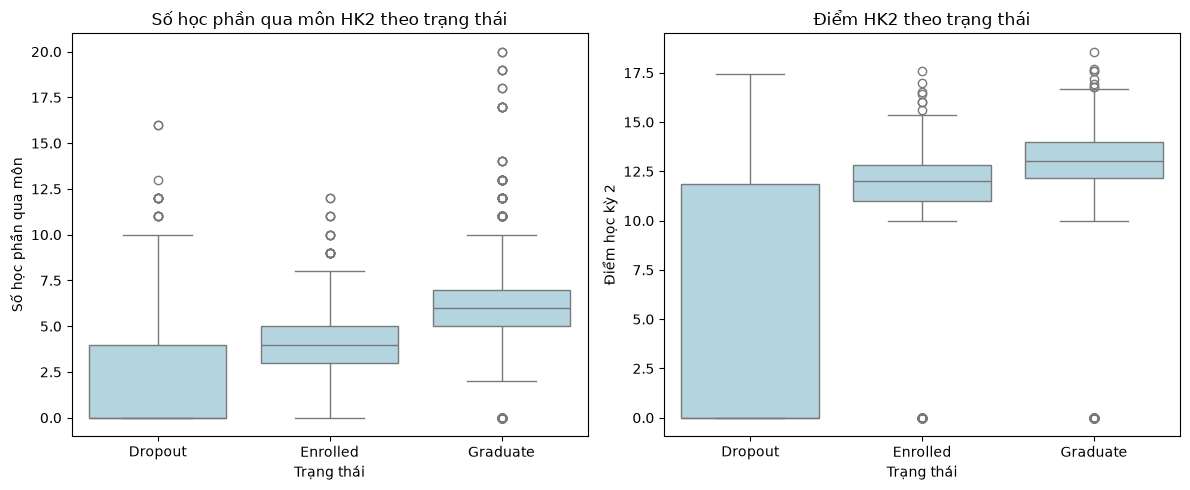

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=train_df,
    x="Target",
    y="Curricular units 2nd sem (approved)",
    order=class_order,
    color="lightblue",
    ax=axes[0]
)

axes[0].set_title("Số học phần qua môn HK2 theo trạng thái")
axes[0].set_xlabel("Trạng thái")
axes[0].set_ylabel("Số học phần qua môn")

sns.boxplot(
    data=train_df,
    x="Target",
    y="Curricular units 2nd sem (grade)",
    order=class_order,
    color="lightblue",
    ax=axes[1]
)

axes[1].set_title("Điểm HK2 theo trạng thái")
axes[1].set_xlabel("Trạng thái")
axes[1].set_ylabel("Điểm học kỳ 2")

plt.tight_layout()
plt.show()

Trên tập Train, trung vị số học phần qua môn HK2 tăng từ khoảng 0 ở nhóm Dropout lên 4 ở Enrolled và 6 ở Graduate. Trung vị điểm HK2 cũng tăng tương ứng, trong khi Enrolled và Graduate có phân phối điểm chồng lấn đáng kể. Hai đặc trưng học tập này có tiềm năng hỗ trợ phân loại, nhưng cần kết hợp thêm các đặc trưng khác và kiểm chứng bằng thực nghiệm mô hình.

#### Kiểm tra mối liên hệ giữa học phí, học bổng và trạng thái sinh viên

In [13]:
finance_cols = [
    "Tuition fees up to date",
    "Debtor",
    "Scholarship holder"
]

finance_tables = {}

for col in finance_cols:
    # Số lượng sinh viên trong từng nhóm
    counts = pd.crosstab(train_df[col], train_df["Target"])
    counts = counts.reindex(columns=class_order, fill_value=0)

    # Tỷ lệ các trạng thái trong từng nhóm
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    finance_tables[col] = percentages

    print(f"\n--- {col} ---")

    result = percentages.round(2)
    result["Số sinh viên"] = counts.sum(axis=1)

    display(result)


--- Tuition fees up to date ---


Target,Dropout,Enrolled,Graduate,Số sinh viên
Tuition fees up to date,,,,
0,86.87,8.11,5.01,419
1,24.78,19.26,55.96,3120



--- Debtor ---


Target,Dropout,Enrolled,Graduate,Số sinh viên
Debtor,,,,
0,28.19,17.97,53.84,3150
1,64.01,17.74,18.25,389



--- Scholarship holder ---


Target,Dropout,Enrolled,Graduate,Số sinh viên
Scholarship holder,,,,
0,38.64,20.08,41.29,2645
1,12.86,11.63,75.50,894


Trên tập huấn luyện, nhóm chưa cập nhật học phí đầy đủ và nhóm có nợ có tỷ lệ bỏ học cao hơn các nhóm đối chiếu. Ngược lại, nhóm nhận học bổng có tỷ lệ bỏ học thấp hơn và tỷ lệ tốt nghiệp cao hơn nhóm không nhận. Các biến tài chính có tiềm năng hỗ trợ dự đoán trạng thái sinh viên, nhưng cần kiểm chứng bằng thực nghiệm mô hình và không diễn giải các mối liên hệ này thành quan hệ nhân quả.

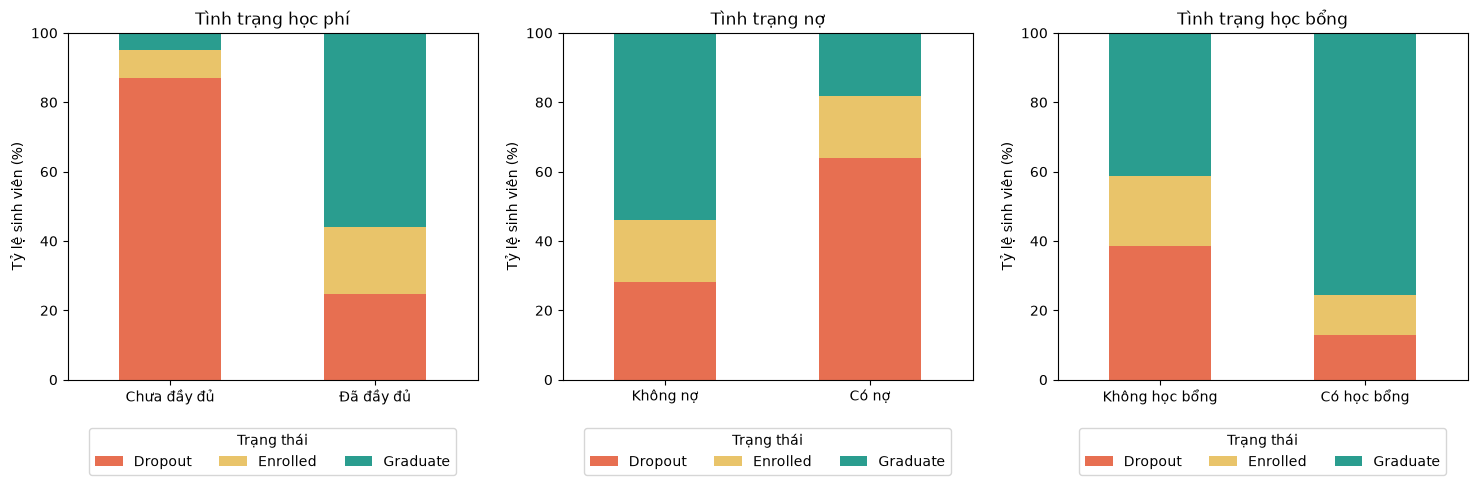

In [14]:
titles = [
    "Tình trạng học phí",
    "Tình trạng nợ",
    "Tình trạng học bổng"
]

group_labels = [
    ["Chưa đầy đủ", "Đã đầy đủ"],
    ["Không nợ", "Có nợ"],
    ["Không học bổng", "Có học bổng"]
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col, title, labels in zip(
    axes, finance_cols, titles, group_labels
):
    finance_tables[col].plot(
        kind="bar",
        stacked=True,
        color=["#e76f51", "#e9c46a", "#2a9d8f"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Tỷ lệ sinh viên (%)")
    ax.set_ylim(0, 100)
    ax.set_xticklabels(labels, rotation=0)
    ax.legend(title="Trạng thái", loc="upper center",
              bbox_to_anchor=(0.5, -0.12), ncol=3)

plt.tight_layout()
plt.show()

- Học phí: nhóm chưa đầy đủ có phần Dropout lớn hơn rõ rệt.
- Nợ: nhóm có nợ có tỷ lệ Dropout cao hơn nhóm không nợ.
- Học bổng: nhóm nhận học bổng có phần Graduate lớn hơn và Dropout nhỏ hơn.
Các biểu đồ nhất quán với ba bảng trước. Nhớ rằng mỗi cột là 100% của một nhóm, không biểu diễn số người.

### Ma trận tương quan

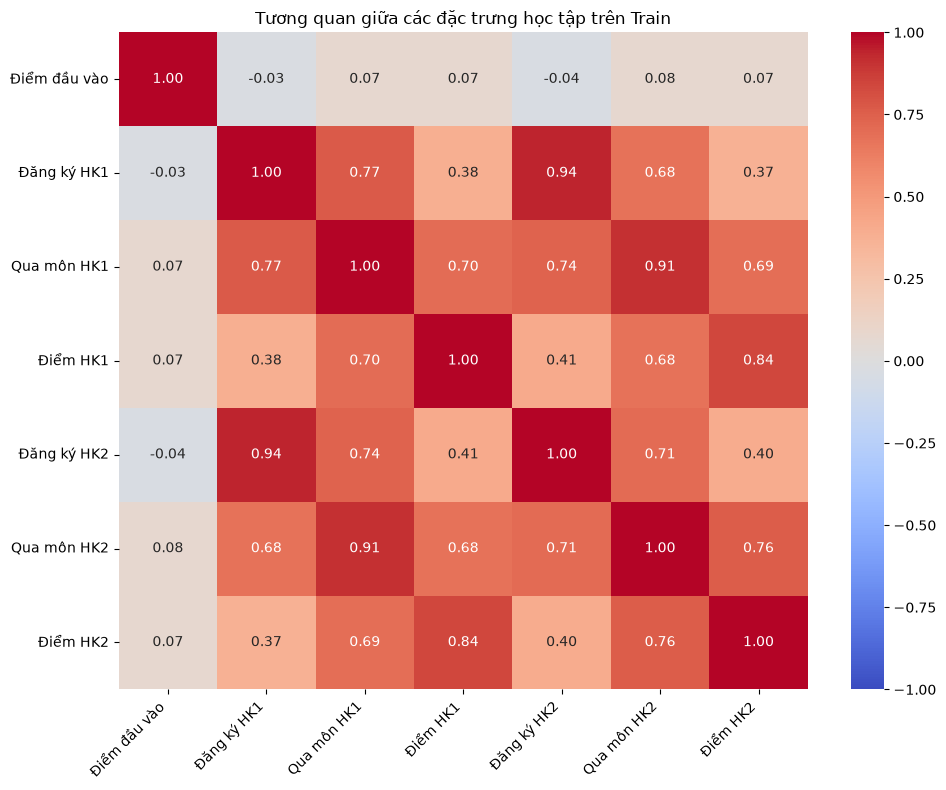

In [15]:
# Chọn các biến định lượng về tuyển sinh và học tập
corr_cols = [
    "Admission grade",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)"
]

# Đặt nhãn ngắn để biểu đồ dễ đọc
short_labels = [
    "Điểm đầu vào",
    "Đăng ký HK1",
    "Qua môn HK1",
    "Điểm HK1",
    "Đăng ký HK2",
    "Qua môn HK2",
    "Điểm HK2"
]

corr_matrix = train_df[corr_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=short_labels,
    yticklabels=short_labels
)

plt.title("Tương quan giữa các đặc trưng học tập trên Train")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Các đặc trưng tương ứng giữa hai học kỳ có tương quan dương mạnh: số học phần đăng ký đạt 0,94, số học phần qua môn đạt 0,91 và điểm học kỳ đạt 0,84. Điều này gợi ý sự trùng lặp một phần thông tin giữa các biến. Điểm đầu vào có tương quan tuyến tính yếu với các đặc trưng học tập đang xét. Việc giữ hoặc loại bỏ đặc trưng sẽ được kiểm chứng bằng cross-validation thay vì chỉ dựa vào hệ số tương quan.

#### Rà soát các giá trị nằm ngoài ngưỡng IQR

In [16]:
# Các biến định lượng cần kiểm tra
check_cols = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 2nd sem (enrolled)"
]

# Tính các phân vị và khoảng tứ phân vị
Q1 = train_df[check_cols].quantile(0.25)
Q3 = train_df[check_cols].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Đánh dấu giá trị nằm ngoài ngưỡng
outside = (
    (train_df[check_cols] < lower) |
    (train_df[check_cols] > upper)
)

iqr_summary = pd.DataFrame({
    "Ngưỡng dưới": lower,
    "Ngưỡng trên": upper,
    "Số ngoài ngưỡng": outside.sum(),
    "Tỷ lệ (%)": outside.mean() * 100
})

iqr_summary.round(2)

,Ngưỡng dưới,Ngưỡng trên,Số ngoài ngưỡng,Tỷ lệ (%)
Age at enrollment,10.00,34.00,358,10.12
Admission grade,92.15,160.55,68,1.92
Curricular units 1st sem (enrolled),2.00,10.00,342,9.66
Curricular units 2nd sem (enrolled),2.00,10.00,300,8.48


Quy tắc 1,5 × IQR đánh dấu 10,12% giá trị tuổi nhập học, 1,92% điểm đầu vào, 9,66% số học phần đăng ký HK1 và 8,48% số học phần đăng ký HK2 nằm ngoài ngưỡng. Những trường hợp này chưa được xác định là lỗi dữ liệu. Vì vậy, nghiên cứu giữ nguyên chúng trong thực nghiệm ban đầu, tránh loại bỏ thông tin khi chưa có căn cứ.